In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay
from itertools import combinations
import pickle

In [2]:
df = pd.read_csv("../StudentsPerformance.csv")

print(df.shape)
print(df.isna().sum())  
df.head()

(1000, 8)
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


race/ethnicity
group A     89
group B    190
group C    319
group D    262
group E    140
Name: count, dtype: int64


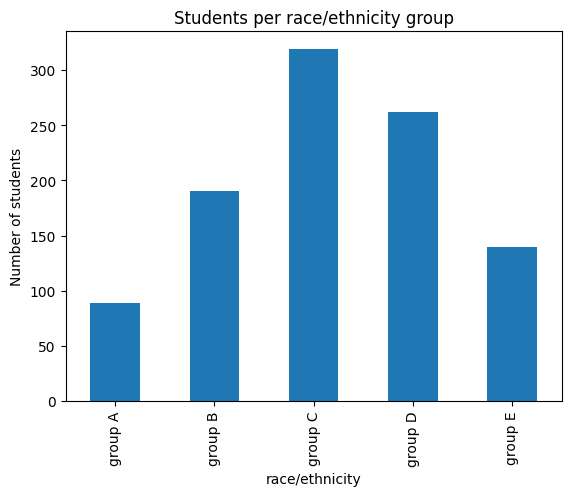

In [3]:
counts = df["race/ethnicity"].value_counts().sort_index()
print(counts)

counts.plot(kind="bar", title="Students per race/ethnicity group")
plt.ylabel("Number of students")
plt.show()

Imbalance classes - with 'Group C' with 319 and 'Group A' with 89.
The model will favor predicting C

In [11]:
# Average test scores for each group
df.groupby("race/ethnicity")[["math score", "reading score", "writing score"]].mean().round(1)

,math score,reading score,writing score
race/ethnicity,,,
group A,61.6,64.7,62.7
group B,63.5,67.4,65.6
group C,64.5,69.1,67.8
group D,67.4,70.0,70.1
group E,73.8,73.0,71.4


In [4]:
X = df[["math score", "reading score", "writing score"]].values
y = df["race/ethnicity"].values

# 75/25 split, stratified so each group keeps its proportion in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=29, stratify=y
)
print(X_train.shape, X_test.shape)

(750, 3) (250, 3)


In [5]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print("Baseline accuracy:", round(accuracy_score(y_test, baseline.predict(X_test)), 4))

Baseline accuracy: 0.32


In [6]:
# Each pipeline = scaler + model
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(random_state=29)),
    "Kernel SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=29)),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    results[name] = accuracy_score(y_test, model.predict(X_test))
    print(f"{name}: {results[name]:.4f}")

Logistic Regression: 0.3600
KNN: 0.3080
Random Forest: 0.2760
Kernel SVM: 0.3560


c:\Users\Janna Hoyne\Desktop\Student Performance\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best model: Logistic Regression
              precision    recall  f1-score   support

     group A       0.00      0.00      0.00        22
     group B       0.00      0.00      0.00        47
     group C       0.35      0.74      0.47        80
     group D       0.39      0.36      0.38        66
     group E       0.37      0.20      0.26        35

    accuracy                           0.36       250
   macro avg       0.22      0.26      0.22       250
weighted avg       0.27      0.36      0.29       250



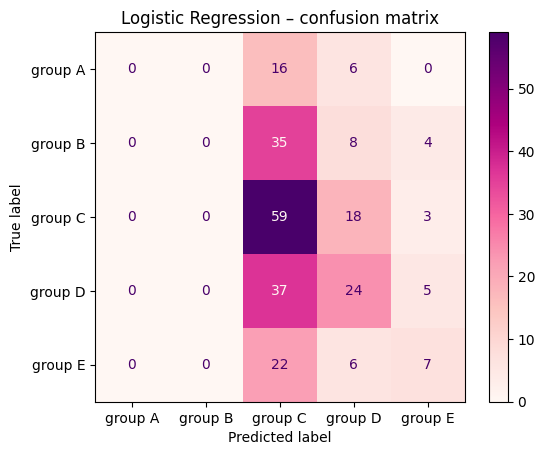

In [7]:
best_name = max(results, key=results.get)
best_model = models[best_name]
print("Best model:", best_name)

y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="RdPu")
plt.title(f"{best_name} – confusion matrix")
plt.show()

In [8]:
feature_names = ["math score", "reading score", "writing score"]
baseline_acc = accuracy_score(y_test, baseline.predict(X_test))

rows = []
for size in [1, 2, 3]:
    for combo in combinations(range(3), size):
        cols = list(combo)
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        model.fit(X_train[:, cols], y_train)   # use only the chosen columns
        acc = accuracy_score(y_test, model.predict(X_test[:, cols]))
        rows.append({
            "features": " + ".join(feature_names[i].replace(" score", "") for i in cols),
            "accuracy": round(acc, 3),
            "vs baseline": round(acc - baseline_acc, 3),
        })

pd.DataFrame(rows).sort_values("accuracy", ascending=False)

,features,accuracy,vs baseline
6,math + reading + writing,0.360,0.040
3,math + reading,0.336,0.016
0,math,0.336,0.016
4,math + writing,0.320,0.000
1,reading,0.320,0.000
5,reading + writing,0.320,0.000
2,writing,0.292,-0.028


In [9]:
with open("../model.pkl", "wb") as f:
    pickle.dump(best_model, f)

print("Saved model.pkl")

Saved model.pkl


In [10]:
loaded = pickle.load(open("../model.pkl", "rb"))

sample = [[72, 72, 74]]
print("Prediction:", loaded.predict(sample)[0])

probs = loaded.predict_proba(sample)[0]
for group, p in zip(loaded.classes_, probs):
    print(f"{group}: {p:.1%}")

Prediction: group D
group A: 6.8%
group B: 16.2%
group C: 30.8%
group D: 31.7%
group E: 14.5%


Logistic Regression mode was the best performing at 36% vs 32% when guessing for C
